# Replay Event Preparation

This notebook converts the validated full-period NASA FIRMS, EPA PM2.5,
and NOAA weather outputs into source-specific replay events.

Each event preserves its original UTC county-hour key and source-specific
measurements. A common event envelope is added so the three sources can
later be replayed at different speeds and with controlled arrival delays.

In [2]:
from pathlib import Path
import hashlib
import json

import numpy as np
import pandas as pd


# Locate the repository reliably.
candidate_project_roots = [
    Path(
        "/Users/VV/Documents/GitHub/smokewatch-replay"
    ),
    Path.cwd(),
    *Path.cwd().parents,
]

project_root = None

for candidate_root in candidate_project_roots:
    candidate_root = candidate_root.resolve()

    if (
        (candidate_root / "notebooks").is_dir()
        and (candidate_root / "data").is_dir()
        and (candidate_root / ".git").exists()
    ):
        project_root = candidate_root
        break

if project_root is None:
    raise FileNotFoundError(
        "Could not locate the smokewatch-replay "
        "repository root."
    )

print("Project root:", project_root)


source_paths = {
    "nasa_firms": (
        project_root
        / "data"
        / "interim"
        / "nasa_firms"
        / "dixie_fire_hourly_county_full_2021-07-13_2021-08-31.csv"
    ),
    "epa_pm25": (
        project_root
        / "data"
        / "interim"
        / "epa_airdata"
        / "dixie_pm25_hourly_county_full_2021-07-13_2021-08-31.csv"
    ),
    "noaa_weather": (
        project_root
        / "data"
        / "interim"
        / "noaa_ghcnh"
        / "dixie_weather_hourly_county_full_2021-07-13_2021-08-31.csv"
    ),
}

integrated_path = (
    project_root
    / "data"
    / "interim"
    / "integrated"
    / "dixie_integrated_hourly_county_full_2021-07-13_2021-08-31.csv"
)


for source_name, source_path in source_paths.items():
    if not source_path.exists():
        raise FileNotFoundError(
            f"{source_name} file not found: "
            f"{source_path}"
        )

if not integrated_path.exists():
    raise FileNotFoundError(
        f"Integrated file not found: "
        f"{integrated_path}"
    )


source_frames = {
    source_name: pd.read_csv(source_path)
    for source_name, source_path
    in source_paths.items()
}

integrated_frame = pd.read_csv(
    integrated_path
)


print("Source files loaded successfully.")

for source_name, source_frame in source_frames.items():
    print(
        source_name,
        source_frame.shape,
    )

print(
    "integrated",
    integrated_frame.shape,
)

Project root: /Users/VV/Documents/GitHub/smokewatch-replay
Source files loaded successfully.
nasa_firms (6000, 8)
epa_pm25 (6000, 9)
noaa_weather (6000, 14)
integrated (6000, 27)


In [3]:
key_columns = [
    "event_hour_utc",
    "county",
]

expected_counties = {
    "Butte",
    "Lassen",
    "Plumas",
    "Shasta",
    "Tehama",
}

expected_start_utc = pd.Timestamp(
    "2021-07-13 00:00:00",
    tz="UTC",
)

expected_end_utc = pd.Timestamp(
    "2021-08-31 23:00:00",
    tz="UTC",
)


def prepare_replay_source(
    source_frame,
    source_name,
):
    prepared_frame = source_frame.copy()

    missing_keys = (
        set(key_columns)
        - set(prepared_frame.columns)
    )

    if missing_keys:
        raise KeyError(
            f"{source_name} is missing keys: "
            f"{sorted(missing_keys)}"
        )

    prepared_frame["event_hour_utc"] = (
        pd.to_datetime(
            prepared_frame["event_hour_utc"],
            utc=True,
            errors="coerce",
        )
    )

    prepared_frame["county"] = (
        prepared_frame["county"]
        .astype("string")
        .str.strip()
    )

    prepared_frame = (
        prepared_frame
        .sort_values(key_columns)
        .reset_index(drop=True)
    )

    assert len(prepared_frame) == 6000

    assert (
        prepared_frame[
            "event_hour_utc"
        ].isna().sum()
        == 0
    )

    assert (
        prepared_frame.duplicated(
            subset=key_columns
        ).sum()
        == 0
    )

    assert (
        set(prepared_frame["county"])
        == expected_counties
    )

    assert (
        prepared_frame.groupby(
            "county"
        ).size().eq(1200).all()
    )

    assert (
        prepared_frame[
            "event_hour_utc"
        ].min()
        == expected_start_utc
    )

    assert (
        prepared_frame[
            "event_hour_utc"
        ].max()
        == expected_end_utc
    )

    print(
        f"{source_name}: validated "
        f"{len(prepared_frame)} rows."
    )

    return prepared_frame


source_frames = {
    source_name: prepare_replay_source(
        source_frame,
        source_name,
    )
    for source_name, source_frame
    in source_frames.items()
}

integrated_frame = prepare_replay_source(
    integrated_frame,
    "integrated",
)


reference_keys = source_frames[
    "nasa_firms"
][key_columns]

for source_name, source_frame in source_frames.items():
    pd.testing.assert_frame_equal(
        source_frame[key_columns],
        reference_keys,
        check_dtype=False,
    )

pd.testing.assert_frame_equal(
    integrated_frame[key_columns],
    reference_keys,
    check_dtype=False,
)

print(
    "All source grids share the same "
    "6,000 county-hour keys."
)

nasa_firms: validated 6000 rows.
epa_pm25: validated 6000 rows.
noaa_weather: validated 6000 rows.
integrated: validated 6000 rows.
All source grids share the same 6,000 county-hour keys.


In [4]:
source_event_frames = {}

for source_name, source_frame in source_frames.items():
    event_frame = source_frame.copy()

    timestamp_token = (
        event_frame["event_hour_utc"]
        .dt.strftime("%Y%m%dT%H%M%SZ")
    )

    county_token = (
        event_frame["county"]
        .astype("string")
        .str.lower()
        .str.replace(" ", "_", regex=False)
    )

    event_ids = (
        source_name
        + "|"
        + county_token
        + "|"
        + timestamp_token
    )

    event_frame.insert(
        0,
        "event_id",
        event_ids,
    )

    event_frame.insert(
        1,
        "source_name",
        source_name,
    )

    event_frame.insert(
        2,
        "source_sequence",
        np.arange(
            len(event_frame),
            dtype="int64",
        ),
    )

    event_frame.insert(
        3,
        "scheduled_event_time_utc",
        event_frame["event_hour_utc"],
    )

    event_frame.insert(
        4,
        "source_row_present",
        True,
    )

    assert len(event_frame) == 6000
    assert event_frame["event_id"].is_unique
    assert event_frame["source_sequence"].is_unique

    source_event_frames[source_name] = (
        event_frame
    )

    print(
        source_name,
        "replay events:",
        len(event_frame),
    )

nasa_firms replay events: 6000
epa_pm25 replay events: 6000
noaa_weather replay events: 6000


In [5]:
def make_json_safe(value):
    if value is None:
        return None

    try:
        if pd.isna(value):
            return None
    except TypeError:
        pass

    if isinstance(value, pd.Timestamp):
        return value.isoformat()

    if isinstance(value, np.generic):
        return value.item()

    return value


def serialize_payload(record):
    safe_record = {
        key: make_json_safe(value)
        for key, value in record.items()
    }

    return json.dumps(
        safe_record,
        sort_keys=True,
        separators=(",", ":"),
        allow_nan=False,
    )


catalog_frames = []

for source_name, event_frame in (
    source_event_frames.items()
):
    original_source_frame = source_frames[
        source_name
    ]

    payload_columns = [
        column
        for column in original_source_frame.columns
        if column not in key_columns
    ]

    payload_records = (
        original_source_frame[
            payload_columns
        ]
        .to_dict(orient="records")
    )

    catalog_frame = event_frame[
        [
            "event_id",
            "source_name",
            "source_sequence",
            "scheduled_event_time_utc",
            "event_hour_utc",
            "county",
            "source_row_present",
        ]
    ].copy()

    catalog_frame["payload_json"] = [
        serialize_payload(record)
        for record in payload_records
    ]

    catalog_frames.append(
        catalog_frame
    )


replay_event_catalog = (
    pd.concat(
        catalog_frames,
        ignore_index=True,
    )
    .sort_values(
        [
            "scheduled_event_time_utc",
            "source_name",
            "county",
        ]
    )
    .reset_index(drop=True)
)

assert len(replay_event_catalog) == 18000
assert replay_event_catalog["event_id"].is_unique

assert (
    replay_event_catalog.groupby(
        "source_name"
    ).size().eq(6000).all()
)

assert (
    replay_event_catalog[
        "payload_json"
    ].isna().sum()
    == 0
)


replay_output_directory = (
    project_root
    / "data"
    / "processed"
    / "replay"
)

replay_output_directory.mkdir(
    parents=True,
    exist_ok=True,
)


saved_event_paths = {}

for source_name, event_frame in (
    source_event_frames.items()
):
    source_output_path = (
        replay_output_directory
        / (
            f"{source_name}_events_full_"
            "2021-07-13_2021-08-31.csv"
        )
    )

    event_frame.to_csv(
        source_output_path,
        index=False,
    )

    saved_event_paths[source_name] = (
        source_output_path
    )


catalog_output_path = (
    replay_output_directory
    / (
        "dixie_replay_event_catalog_full_"
        "2021-07-13_2021-08-31.csv"
    )
)

replay_event_catalog.to_csv(
    catalog_output_path,
    index=False,
)


def calculate_sha256(file_path):
    file_hash = hashlib.sha256()

    with open(file_path, "rb") as file_handle:
        for file_chunk in iter(
            lambda: file_handle.read(1024 * 1024),
            b"",
        ):
            file_hash.update(file_chunk)

    return file_hash.hexdigest()


manifest_records = []

for source_name, source_output_path in (
    saved_event_paths.items()
):
    manifest_records.append(
        {
            "dataset": source_name,
            "rows": len(
                source_event_frames[
                    source_name
                ]
            ),
            "file_path": str(
                source_output_path
            ),
            "sha256": calculate_sha256(
                source_output_path
            ),
        }
    )

manifest_records.append(
    {
        "dataset": "combined_catalog",
        "rows": len(replay_event_catalog),
        "file_path": str(
            catalog_output_path
        ),
        "sha256": calculate_sha256(
            catalog_output_path
        ),
    }
)

replay_manifest = pd.DataFrame(
    manifest_records
)

manifest_output_path = (
    replay_output_directory
    / "replay_manifest.csv"
)

replay_manifest.to_csv(
    manifest_output_path,
    index=False,
)


print(
    "Replay event preparation completed successfully."
)

print(
    "Combined replay events:",
    len(replay_event_catalog),
)

print(
    "Unique event IDs:",
    replay_event_catalog[
        "event_id"
    ].nunique(),
)

print(
    "Replay output directory:",
    replay_output_directory,
)

display(replay_manifest)

Replay event preparation completed successfully.
Combined replay events: 18000
Unique event IDs: 18000
Replay output directory: /Users/VV/Documents/GitHub/smokewatch-replay/data/processed/replay


,dataset,rows,file_path,sha256
0,nasa_firms,6000,/Users/VV/Documents/GitHub/smokewatch-replay/d...,570a89625d852565e94bee4c63c153cdc7ad1f0ff85717...
1,epa_pm25,6000,/Users/VV/Documents/GitHub/smokewatch-replay/d...,430ffcfae8f5f10f9d90436b4eef364e921f46b0bda942...
2,noaa_weather,6000,/Users/VV/Documents/GitHub/smokewatch-replay/d...,dc6b68c2b03e8241a4ada2c64683701305e926427abdcc...
3,combined_catalog,18000,/Users/VV/Documents/GitHub/smokewatch-replay/d...,4ccbf2ee3238fcbade2eb24996b918afe46a421eecfc03...


## Controlled Replay Scenarios

The replay experiment uses three speeds and three delayed-record profiles,
creating nine controlled scenarios.

The same event IDs are used in every scenario. Deterministic selection
ensures that the same records are delayed whenever the same delay profile
is used, allowing fair comparisons between replay speeds.

In [6]:
replay_speed_profiles = pd.DataFrame(
    [
        {
            "speed_name": "slow",
            "speedup_factor": 3600,
            "replay_seconds_per_event_hour": 1.0,
        },
        {
            "speed_name": "medium",
            "speedup_factor": 36000,
            "replay_seconds_per_event_hour": 0.1,
        },
        {
            "speed_name": "fast",
            "speedup_factor": 360000,
            "replay_seconds_per_event_hour": 0.01,
        },
    ]
)

delay_profiles = pd.DataFrame(
    [
        {
            "delay_profile": "none",
            "delay_probability": 0.00,
            "minimum_delay_event_hours": 0,
            "maximum_delay_event_hours": 0,
        },
        {
            "delay_profile": "moderate",
            "delay_probability": 0.10,
            "minimum_delay_event_hours": 1,
            "maximum_delay_event_hours": 3,
        },
        {
            "delay_profile": "severe",
            "delay_probability": 0.25,
            "minimum_delay_event_hours": 3,
            "maximum_delay_event_hours": 12,
        },
    ]
)

scenario_config = (
    replay_speed_profiles
    .merge(
        delay_profiles,
        how="cross",
    )
)

scenario_config["scenario_id"] = (
    scenario_config["speed_name"]
    + "__"
    + scenario_config["delay_profile"]
)

scenario_config.insert(
    0,
    "scenario_number",
    np.arange(
        1,
        len(scenario_config) + 1,
        dtype="int64",
    ),
)

assert len(scenario_config) == 9
assert scenario_config["scenario_id"].is_unique

display(scenario_config)

,scenario_number,speed_name,speedup_factor,replay_seconds_per_event_hour,delay_profile,delay_probability,minimum_delay_event_hours,maximum_delay_event_hours,scenario_id
0,1,slow,3600,1.00,none,0.00,0,0,slow__none
1,2,slow,3600,1.00,moderate,0.10,1,3,slow__moderate
2,3,slow,3600,1.00,severe,0.25,3,12,slow__severe
3,4,medium,36000,0.10,none,0.00,0,0,medium__none
4,5,medium,36000,0.10,moderate,0.10,1,3,medium__moderate
5,6,medium,36000,0.10,severe,0.25,3,12,medium__severe
6,7,fast,360000,0.01,none,0.00,0,0,fast__none
7,8,fast,360000,0.01,moderate,0.10,1,3,fast__moderate
8,9,fast,360000,0.01,severe,0.25,3,12,fast__severe


In [7]:
def stable_fraction(
    identifier,
    salt,
):
    encoded_value = (
        f"{identifier}|{salt}|226"
        .encode("utf-8")
    )

    digest = hashlib.sha256(
        encoded_value
    ).digest()

    integer_value = int.from_bytes(
        digest[:8],
        byteorder="big",
        signed=False,
    )

    return integer_value / (2 ** 64)


scenario_event_base = (
    replay_event_catalog[
        [
            "event_id",
            "source_name",
            "source_sequence",
            "event_hour_utc",
            "county",
        ]
    ]
    .copy()
)

scenario_event_base[
    "event_hour_utc"
] = pd.to_datetime(
    scenario_event_base[
        "event_hour_utc"
    ],
    utc=True,
    errors="coerce",
)

scenario_event_base[
    "delay_selection_fraction"
] = (
    scenario_event_base["event_id"]
    .map(
        lambda event_id: stable_fraction(
            event_id,
            "selection",
        )
    )
)

scenario_event_base[
    "delay_duration_fraction"
] = (
    scenario_event_base["event_id"]
    .map(
        lambda event_id: stable_fraction(
            event_id,
            "duration",
        )
    )
)

assert len(scenario_event_base) == 18000

assert (
    scenario_event_base[
        "event_id"
    ].is_unique
)

assert (
    scenario_event_base[
        "event_hour_utc"
    ].isna().sum()
    == 0
)

assert (
    scenario_event_base[
        "delay_selection_fraction"
    ].between(0, 1, inclusive="left").all()
)

assert (
    scenario_event_base[
        "delay_duration_fraction"
    ].between(0, 1, inclusive="left").all()
)

print(
    "Deterministic delay values created for",
    len(scenario_event_base),
    "events.",
)

Deterministic delay values created for 18000 events.


In [8]:
replay_event_start_utc = (
    scenario_event_base[
        "event_hour_utc"
    ].min()
)


def build_scenario_schedule(
    configuration,
):
    speedup_factor = float(
        configuration[
            "speedup_factor"
        ]
    )

    delay_probability = float(
        configuration[
            "delay_probability"
        ]
    )

    minimum_delay = int(
        configuration[
            "minimum_delay_event_hours"
        ]
    )

    maximum_delay = int(
        configuration[
            "maximum_delay_event_hours"
        ]
    )

    schedule = (
        scenario_event_base.copy()
    )

    schedule["scenario_id"] = (
        configuration["scenario_id"]
    )

    schedule["speed_name"] = (
        configuration["speed_name"]
    )

    schedule["speedup_factor"] = (
        speedup_factor
    )

    schedule["delay_profile"] = (
        configuration["delay_profile"]
    )

    schedule["is_delayed"] = (
        schedule[
            "delay_selection_fraction"
        ]
        < delay_probability
    )

    if maximum_delay > 0:
        delay_range_size = (
            maximum_delay
            - minimum_delay
            + 1
        )

        candidate_delay_hours = (
            minimum_delay
            + np.floor(
                schedule[
                    "delay_duration_fraction"
                ]
                * delay_range_size
            ).astype("int64")
        )
    else:
        candidate_delay_hours = (
            pd.Series(
                0,
                index=schedule.index,
                dtype="int64",
            )
        )

    schedule[
        "injected_delay_event_hours"
    ] = np.where(
        schedule["is_delayed"],
        candidate_delay_hours,
        0,
    ).astype("int64")

    schedule[
        "base_arrival_offset_seconds"
    ] = (
        (
            schedule["event_hour_utc"]
            - replay_event_start_utc
        )
        .dt.total_seconds()
        / speedup_factor
    )

    schedule[
        "injected_delay_replay_seconds"
    ] = (
        schedule[
            "injected_delay_event_hours"
        ]
        * 3600
        / speedup_factor
    )

    schedule[
        "scheduled_arrival_offset_seconds"
    ] = (
        schedule[
            "base_arrival_offset_seconds"
        ]
        + schedule[
            "injected_delay_replay_seconds"
        ]
    )

    schedule = (
        schedule
        .sort_values(
            [
                "scheduled_arrival_offset_seconds",
                "source_name",
                "event_id",
            ]
        )
        .reset_index(drop=True)
    )

    schedule.insert(
        0,
        "scenario_sequence",
        np.arange(
            len(schedule),
            dtype="int64",
        ),
    )

    return schedule

In [9]:
scenario_schedule_frames = []

for _, configuration in (
    scenario_config.iterrows()
):
    scenario_schedule = (
        build_scenario_schedule(
            configuration
        )
    )

    assert len(scenario_schedule) == 18000

    assert (
        scenario_schedule[
            "event_id"
        ].is_unique
    )

    scenario_schedule_frames.append(
        scenario_schedule
    )

    print(
        configuration["scenario_id"],
        "created:",
        len(scenario_schedule),
        "events",
    )


all_scenario_schedules = pd.concat(
    scenario_schedule_frames,
    ignore_index=True,
)

assert len(all_scenario_schedules) == 162000

print(
    "Total scheduled scenario events:",
    len(all_scenario_schedules),
)

slow__none created: 18000 events
slow__moderate created: 18000 events
slow__severe created: 18000 events
medium__none created: 18000 events
medium__moderate created: 18000 events
medium__severe created: 18000 events
fast__none created: 18000 events
fast__moderate created: 18000 events
fast__severe created: 18000 events
Total scheduled scenario events: 162000


In [10]:
reference_event_ids = set(
    replay_event_catalog[
        "event_id"
    ]
)

scenario_validation_records = []

for scenario_id, scenario_frame in (
    all_scenario_schedules.groupby(
        "scenario_id"
    )
):
    assert len(scenario_frame) == 18000

    assert (
        scenario_frame[
            "event_id"
        ].nunique()
        == 18000
    )

    assert (
        set(scenario_frame["event_id"])
        == reference_event_ids
    )

    delay_profile = (
        scenario_frame[
            "delay_profile"
        ].iloc[0]
    )

    delayed_frame = scenario_frame[
        scenario_frame["is_delayed"]
    ]

    if delay_profile == "none":
        assert len(delayed_frame) == 0

    elif delay_profile == "moderate":
        assert (
            delayed_frame[
                "injected_delay_event_hours"
            ].between(1, 3).all()
        )

    elif delay_profile == "severe":
        assert (
            delayed_frame[
                "injected_delay_event_hours"
            ].between(3, 12).all()
        )

    speedup_factor = float(
        scenario_frame[
            "speedup_factor"
        ].iloc[0]
    )

    nominal_end_seconds = (
        (
            expected_end_utc
            - expected_start_utc
        ).total_seconds()
        / speedup_factor
    )

    scheduled_end_seconds = (
        scenario_frame[
            "scheduled_arrival_offset_seconds"
        ].max()
    )

    scenario_validation_records.append(
        {
            "scenario_id": scenario_id,
            "speed_name": scenario_frame[
                "speed_name"
            ].iloc[0],
            "speedup_factor": speedup_factor,
            "delay_profile": delay_profile,
            "event_count": len(
                scenario_frame
            ),
            "delayed_event_count": len(
                delayed_frame
            ),
            "delayed_event_percent": (
                len(delayed_frame)
                / len(scenario_frame)
                * 100
            ),
            "maximum_delay_event_hours": (
                scenario_frame[
                    "injected_delay_event_hours"
                ].max()
            ),
            "nominal_end_seconds": (
                nominal_end_seconds
            ),
            "scheduled_end_seconds": (
                scheduled_end_seconds
            ),
            "duration_extension_seconds": (
                scheduled_end_seconds
                - nominal_end_seconds
            ),
        }
    )


scenario_summary = (
    pd.DataFrame(
        scenario_validation_records
    )
    .sort_values(
        [
            "speedup_factor",
            "delay_profile",
        ]
    )
    .reset_index(drop=True)
)

assert len(scenario_summary) == 9

assert (
    scenario_summary.groupby(
        "delay_profile"
    )["delayed_event_count"]
    .nunique()
    .eq(1)
    .all()
)

print(
    "All nine scenarios validated successfully."
)

display(scenario_summary)

All nine scenarios validated successfully.


,scenario_id,speed_name,speedup_factor,delay_profile,event_count,delayed_event_count,delayed_event_percent,maximum_delay_event_hours,nominal_end_seconds,scheduled_end_seconds,duration_extension_seconds
0,slow__moderate,slow,3600.0,moderate,18000,1872,10.400000,3,1199.00,1200.00,1.00
1,slow__none,slow,3600.0,none,18000,0,0.000000,0,1199.00,1199.00,0.00
2,slow__severe,slow,3600.0,severe,18000,4490,24.944444,12,1199.00,1211.00,12.00
3,medium__moderate,medium,36000.0,moderate,18000,1872,10.400000,3,119.90,120.00,0.10
4,medium__none,medium,36000.0,none,18000,0,0.000000,0,119.90,119.90,0.00
5,medium__severe,medium,36000.0,severe,18000,4490,24.944444,12,119.90,121.10,1.20
6,fast__moderate,fast,360000.0,moderate,18000,1872,10.400000,3,11.99,12.00,0.01
7,fast__none,fast,360000.0,none,18000,0,0.000000,0,11.99,11.99,0.00
8,fast__severe,fast,360000.0,severe,18000,4490,24.944444,12,11.99,12.11,0.12


In [11]:
scenario_output_directory = (
    replay_output_directory
    / "scenarios"
)

scenario_output_directory.mkdir(
    parents=True,
    exist_ok=True,
)

scenario_manifest_records = []

for scenario_id, scenario_frame in (
    all_scenario_schedules.groupby(
        "scenario_id"
    )
):
    scenario_output_path = (
        scenario_output_directory
        / f"{scenario_id}.csv"
    )

    scenario_frame.to_csv(
        scenario_output_path,
        index=False,
    )

    reloaded_schedule_keys = pd.read_csv(
        scenario_output_path,
        usecols=[
            "scenario_id",
            "event_id",
        ],
    )

    assert len(reloaded_schedule_keys) == 18000

    assert (
        reloaded_schedule_keys[
            "event_id"
        ].is_unique
    )

    scenario_manifest_records.append(
        {
            "scenario_id": scenario_id,
            "rows": len(scenario_frame),
            "file_path": str(
                scenario_output_path
            ),
            "sha256": calculate_sha256(
                scenario_output_path
            ),
        }
    )


scenario_config_output_path = (
    scenario_output_directory
    / "scenario_config.csv"
)

scenario_summary_output_path = (
    scenario_output_directory
    / "scenario_summary.csv"
)

scenario_manifest_output_path = (
    scenario_output_directory
    / "scenario_manifest.csv"
)


scenario_config.to_csv(
    scenario_config_output_path,
    index=False,
)

scenario_summary.to_csv(
    scenario_summary_output_path,
    index=False,
)

scenario_manifest = pd.DataFrame(
    scenario_manifest_records
)

scenario_manifest.to_csv(
    scenario_manifest_output_path,
    index=False,
)


print(
    "Replay scenario schedules saved successfully."
)

print(
    "Scenario count:",
    len(scenario_manifest),
)

print(
    "Total scheduled rows:",
    scenario_manifest["rows"].sum(),
)

print(
    "Output directory:",
    scenario_output_directory,
)

display(scenario_manifest)

Replay scenario schedules saved successfully.
Scenario count: 9
Total scheduled rows: 162000
Output directory: /Users/VV/Documents/GitHub/smokewatch-replay/data/processed/replay/scenarios


,scenario_id,rows,file_path,sha256
0,fast__moderate,18000,/Users/VV/Documents/GitHub/smokewatch-replay/d...,216d58b0f796e9c84b4241514684d837ace2b70883b4e8...
1,fast__none,18000,/Users/VV/Documents/GitHub/smokewatch-replay/d...,a2cf08c22d65de47b8fc0fde9cc2a76e91d2af007f6789...
2,fast__severe,18000,/Users/VV/Documents/GitHub/smokewatch-replay/d...,af4e956ae98da6b5fcfe36141b262cd50ade5f9868602d...
3,medium__moderate,18000,/Users/VV/Documents/GitHub/smokewatch-replay/d...,e192b0363e25ad47799a5beb41e4ea2092bbd3276dbe51...
4,medium__none,18000,/Users/VV/Documents/GitHub/smokewatch-replay/d...,16daea324d2ca14072202a378a98ab305e91c1c7ecee60...
5,medium__severe,18000,/Users/VV/Documents/GitHub/smokewatch-replay/d...,3f44c11b8773ba8ca2f15031d8661179e5a55c6ce05abc...
6,slow__moderate,18000,/Users/VV/Documents/GitHub/smokewatch-replay/d...,f53eb19b6b18b15614459244021191636d6df3a8b8ab53...
7,slow__none,18000,/Users/VV/Documents/GitHub/smokewatch-replay/d...,7af2448f8fd7223078ce1021c78530583df26e38801404...
8,slow__severe,18000,/Users/VV/Documents/GitHub/smokewatch-replay/d...,24e7d834c5317027e7aad30db85500f64122ddcfca88fc...


## Controlled Replay Processing Simulation

This simulation tests how replay speed and delayed records affect a
processor with a fixed capacity of 500 events per second.

For each event, the simulation measures queue wait, processing latency,
end-to-end latency, and freshness lag. A three-event-hour watermark is
used to measure timely join completeness and result correctness.

These are controlled simulation results. They should not be presented
as measured Kafka or Spark performance.

In [12]:
processing_capacity_events_per_second = 500.0

service_time_seconds_per_event = (
    1.0
    / processing_capacity_events_per_second
)

allowed_lateness_event_hours = 3.0

expected_events_per_scenario = 18000
expected_join_keys_per_scenario = 6000

events_per_historical_hour = (
    expected_events_per_scenario
    / 1200
)

assert events_per_historical_hour == 15

simulation_parameters = pd.DataFrame(
    [
        {
            "processing_capacity_events_per_second":
                processing_capacity_events_per_second,
            "service_time_seconds_per_event":
                service_time_seconds_per_event,
            "allowed_lateness_event_hours":
                allowed_lateness_event_hours,
            "events_per_historical_hour":
                events_per_historical_hour,
            "events_per_scenario":
                expected_events_per_scenario,
            "join_keys_per_scenario":
                expected_join_keys_per_scenario,
        }
    ]
)

display(simulation_parameters)

,processing_capacity_events_per_second,service_time_seconds_per_event,allowed_lateness_event_hours,events_per_historical_hour,events_per_scenario,join_keys_per_scenario
0,500.0,0.002,3.0,15.0,18000,6000


In [13]:
def simulate_scenario_processing(
    scenario_schedule,
):
    simulated_events = (
        scenario_schedule
        .sort_values(
            [
                "scheduled_arrival_offset_seconds",
                "scenario_sequence",
            ]
        )
        .reset_index(drop=True)
        .copy()
    )

    arrival_offsets = (
        simulated_events[
            "scheduled_arrival_offset_seconds"
        ]
        .to_numpy(dtype=float)
    )

    event_count = len(simulated_events)

    processing_start_offsets = np.empty(
        event_count,
        dtype=float,
    )

    completion_offsets = np.empty(
        event_count,
        dtype=float,
    )

    server_available_offset = 0.0

    for event_index in range(event_count):
        processing_start_offset = max(
            arrival_offsets[event_index],
            server_available_offset,
        )

        completion_offset = (
            processing_start_offset
            + service_time_seconds_per_event
        )

        processing_start_offsets[
            event_index
        ] = processing_start_offset

        completion_offsets[
            event_index
        ] = completion_offset

        server_available_offset = (
            completion_offset
        )

    simulated_events[
        "processing_start_offset_seconds"
    ] = processing_start_offsets

    simulated_events[
        "processing_completion_offset_seconds"
    ] = completion_offsets

    simulated_events[
        "queue_wait_seconds"
    ] = (
        processing_start_offsets
        - arrival_offsets
    )

    simulated_events[
        "processing_latency_seconds"
    ] = (
        completion_offsets
        - arrival_offsets
    )

    simulated_events[
        "end_to_end_latency_seconds"
    ] = (
        completion_offsets
        - simulated_events[
            "base_arrival_offset_seconds"
        ]
    )

    simulated_events[
        "freshness_lag_event_hours"
    ] = (
        simulated_events[
            "end_to_end_latency_seconds"
        ]
        * simulated_events[
            "speedup_factor"
        ]
        / 3600
    )

    completed_by_arrival = np.searchsorted(
        completion_offsets,
        arrival_offsets,
        side="right",
    )

    simulated_events[
        "queue_depth_on_arrival"
    ] = (
        np.arange(
            1,
            event_count + 1,
        )
        - completed_by_arrival
    )

    simulated_events[
        "watermark_deadline_offset_seconds"
    ] = (
        simulated_events[
            "base_arrival_offset_seconds"
        ]
        + (
            allowed_lateness_event_hours
            * 3600
            / simulated_events[
                "speedup_factor"
            ]
        )
    )

    simulated_events[
        "late_at_watermark"
    ] = (
        simulated_events[
            "processing_completion_offset_seconds"
        ]
        > simulated_events[
            "watermark_deadline_offset_seconds"
        ]
    )

    return simulated_events

In [14]:
simulated_event_frames = []

for scenario_id, scenario_schedule in (
    all_scenario_schedules.groupby(
        "scenario_id",
        sort=False,
    )
):
    simulated_scenario = (
        simulate_scenario_processing(
            scenario_schedule
        )
    )

    assert (
        len(simulated_scenario)
        == expected_events_per_scenario
    )

    assert (
        simulated_scenario[
            "event_id"
        ].is_unique
    )

    assert (
        simulated_scenario[
            "processing_latency_seconds"
        ].ge(0).all()
    )

    assert (
        simulated_scenario[
            "queue_wait_seconds"
        ].ge(0).all()
    )

    simulated_event_frames.append(
        simulated_scenario
    )

    print(
        scenario_id,
        "simulated:",
        len(simulated_scenario),
        "events",
    )


all_simulated_events = pd.concat(
    simulated_event_frames,
    ignore_index=True,
)

assert len(all_simulated_events) == 162000

print(
    "Total simulated events:",
    len(all_simulated_events),
)

slow__none simulated: 18000 events
slow__moderate simulated: 18000 events
slow__severe simulated: 18000 events
medium__none simulated: 18000 events
medium__moderate simulated: 18000 events
medium__severe simulated: 18000 events
fast__none simulated: 18000 events
fast__moderate simulated: 18000 events
fast__severe simulated: 18000 events
Total simulated events: 162000


In [15]:
join_result_frames = []

for scenario_id, simulated_scenario in (
    all_simulated_events.groupby(
        "scenario_id",
        sort=False,
    )
):
    speedup_factor = float(
        simulated_scenario[
            "speedup_factor"
        ].iloc[0]
    )

    join_results = (
        simulated_scenario
        .groupby(
            [
                "event_hour_utc",
                "county",
            ],
            as_index=False,
        )
        .agg(
            source_count=(
                "source_name",
                "nunique",
            ),
            source_event_count=(
                "event_id",
                "size",
            ),
            base_arrival_offset_seconds=(
                "base_arrival_offset_seconds",
                "min",
            ),
            first_source_completion_seconds=(
                "processing_completion_offset_seconds",
                "min",
            ),
            join_completion_seconds=(
                "processing_completion_offset_seconds",
                "max",
            ),
            late_source_event_count=(
                "late_at_watermark",
                "sum",
            ),
        )
    )

    join_results["scenario_id"] = (
        scenario_id
    )

    join_results["speedup_factor"] = (
        speedup_factor
    )

    join_results[
        "watermark_deadline_seconds"
    ] = (
        join_results[
            "base_arrival_offset_seconds"
        ]
        + (
            allowed_lateness_event_hours
            * 3600
            / speedup_factor
        )
    )

    join_results[
        "join_wait_seconds"
    ] = (
        join_results[
            "join_completion_seconds"
        ]
        - join_results[
            "first_source_completion_seconds"
        ]
    )

    join_results[
        "final_join_complete"
    ] = (
        join_results["source_count"].eq(3)
        & join_results[
            "source_event_count"
        ].eq(3)
    )

    join_results[
        "timely_join_complete"
    ] = (
        join_results[
            "final_join_complete"
        ]
        & (
            join_results[
                "join_completion_seconds"
            ]
            <= join_results[
                "watermark_deadline_seconds"
            ]
        )
    )

    join_results[
        "watermark_result_correct"
    ] = (
        join_results[
            "timely_join_complete"
        ]
    )

    assert (
        len(join_results)
        == expected_join_keys_per_scenario
    )

    assert (
        join_results[
            "final_join_complete"
        ].all()
    )

    join_result_frames.append(
        join_results
    )


all_join_results = pd.concat(
    join_result_frames,
    ignore_index=True,
)

assert len(all_join_results) == 54000

print(
    "Total simulated join results:",
    len(all_join_results),
)

Total simulated join results: 54000


In [16]:
event_metric_records = []

for scenario_id, simulated_scenario in (
    all_simulated_events.groupby(
        "scenario_id"
    )
):
    speedup_factor = float(
        simulated_scenario[
            "speedup_factor"
        ].iloc[0]
    )

    replay_seconds_per_event_hour = (
        3600
        / speedup_factor
    )

    offered_input_rate = (
        events_per_historical_hour
        / replay_seconds_per_event_hour
    )

    processing_end_seconds = (
        simulated_scenario[
            "processing_completion_offset_seconds"
        ].max()
    )

    event_metric_records.append(
        {
            "scenario_id": scenario_id,
            "speed_name": simulated_scenario[
                "speed_name"
            ].iloc[0],
            "delay_profile": simulated_scenario[
                "delay_profile"
            ].iloc[0],
            "speedup_factor": speedup_factor,
            "offered_input_rate_eps":
                offered_input_rate,
            "processing_capacity_eps":
                processing_capacity_events_per_second,
            "offered_to_capacity_ratio": (
                offered_input_rate
                / processing_capacity_events_per_second
            ),
            "event_count": len(
                simulated_scenario
            ),
            "processing_end_seconds":
                processing_end_seconds,
            "achieved_throughput_eps": (
                len(simulated_scenario)
                / processing_end_seconds
            ),
            "maximum_queue_depth": int(
                simulated_scenario[
                    "queue_depth_on_arrival"
                ].max()
            ),
            "mean_processing_latency_seconds": (
                simulated_scenario[
                    "processing_latency_seconds"
                ].mean()
            ),
            "p95_processing_latency_seconds": (
                simulated_scenario[
                    "processing_latency_seconds"
                ].quantile(0.95)
            ),
            "p99_processing_latency_seconds": (
                simulated_scenario[
                    "processing_latency_seconds"
                ].quantile(0.99)
            ),
            "p95_freshness_lag_event_hours": (
                simulated_scenario[
                    "freshness_lag_event_hours"
                ].quantile(0.95)
            ),
            "late_event_count": int(
                simulated_scenario[
                    "late_at_watermark"
                ].sum()
            ),
        }
    )


event_metrics = pd.DataFrame(
    event_metric_records
)


join_metrics = (
    all_join_results
    .groupby(
        "scenario_id",
        as_index=False,
    )
    .agg(
        join_key_count=(
            "event_hour_utc",
            "size",
        ),
        final_join_complete_keys=(
            "final_join_complete",
            "sum",
        ),
        timely_join_complete_keys=(
            "timely_join_complete",
            "sum",
        ),
        watermark_correct_keys=(
            "watermark_result_correct",
            "sum",
        ),
        keys_with_late_sources=(
            "late_source_event_count",
            lambda values: values.gt(0).sum(),
        ),
        mean_join_wait_seconds=(
            "join_wait_seconds",
            "mean",
        ),
        p95_join_wait_seconds=(
            "join_wait_seconds",
            lambda values: values.quantile(0.95),
        ),
    )
)


simulation_metrics = (
    event_metrics
    .merge(
        join_metrics,
        on="scenario_id",
        how="left",
        validate="one_to_one",
    )
)

simulation_metrics[
    "final_join_completeness_percent"
] = (
    simulation_metrics[
        "final_join_complete_keys"
    ]
    / simulation_metrics[
        "join_key_count"
    ]
    * 100
)

simulation_metrics[
    "timely_join_completeness_percent"
] = (
    simulation_metrics[
        "timely_join_complete_keys"
    ]
    / simulation_metrics[
        "join_key_count"
    ]
    * 100
)

simulation_metrics[
    "watermark_correctness_percent"
] = (
    simulation_metrics[
        "watermark_correct_keys"
    ]
    / simulation_metrics[
        "join_key_count"
    ]
    * 100
)

assert len(simulation_metrics) == 9

assert (
    simulation_metrics[
        "final_join_completeness_percent"
    ].eq(100).all()
)

print(
    "All simulation metrics calculated successfully."
)

display(
    simulation_metrics[
        [
            "scenario_id",
            "offered_input_rate_eps",
            "achieved_throughput_eps",
            "maximum_queue_depth",
            "p95_processing_latency_seconds",
            "p95_freshness_lag_event_hours",
            "timely_join_completeness_percent",
            "watermark_correctness_percent",
        ]
    ]
)

All simulation metrics calculated successfully.


,scenario_id,offered_input_rate_eps,achieved_throughput_eps,maximum_queue_depth,p95_processing_latency_seconds,p95_freshness_lag_event_hours,timely_join_completeness_percent,watermark_correctness_percent
0,fast__moderate,1500.0,500.000000,12002,22.8040,2280.410,0.066667,0.066667
1,fast__none,1500.0,500.000000,12006,22.8060,2280.600,0.066667,0.066667
2,fast__severe,1500.0,500.000000,11975,22.7881,2280.410,0.033333,0.033333
3,medium__moderate,150.0,149.990001,21,0.0300,2.200,90.183333,90.183333
4,medium__none,150.0,150.087551,15,0.0300,0.300,100.000000,100.000000
5,medium__severe,150.0,148.632580,25,0.0320,11.020,42.000000,42.000000
6,slow__moderate,15.0,14.999900,21,0.0300,2.016,90.183333,90.183333
7,slow__none,15.0,15.012135,15,0.0300,0.030,100.000000,100.000000
8,slow__severe,15.0,14.863700,25,0.0320,11.002,42.000000,42.000000


In [17]:
simulation_output_directory = (
    replay_output_directory
    / "simulation_results"
)

simulation_output_directory.mkdir(
    parents=True,
    exist_ok=True,
)

simulation_metrics_path = (
    simulation_output_directory
    / "simulation_metrics.csv"
)

join_results_path = (
    simulation_output_directory
    / "join_results.csv"
)

simulation_parameters_path = (
    simulation_output_directory
    / "simulation_parameters.csv"
)

simulation_metrics.to_csv(
    simulation_metrics_path,
    index=False,
)

all_join_results.to_csv(
    join_results_path,
    index=False,
)

simulation_parameters.to_csv(
    simulation_parameters_path,
    index=False,
)


simulation_result_manifest = pd.DataFrame(
    [
        {
            "dataset": "simulation_metrics",
            "rows": len(
                simulation_metrics
            ),
            "file_path": str(
                simulation_metrics_path
            ),
            "sha256": calculate_sha256(
                simulation_metrics_path
            ),
        },
        {
            "dataset": "join_results",
            "rows": len(
                all_join_results
            ),
            "file_path": str(
                join_results_path
            ),
            "sha256": calculate_sha256(
                join_results_path
            ),
        },
        {
            "dataset": "simulation_parameters",
            "rows": len(
                simulation_parameters
            ),
            "file_path": str(
                simulation_parameters_path
            ),
            "sha256": calculate_sha256(
                simulation_parameters_path
            ),
        },
    ]
)

simulation_manifest_path = (
    simulation_output_directory
    / "simulation_manifest.csv"
)

simulation_result_manifest.to_csv(
    simulation_manifest_path,
    index=False,
)


print(
    "Simulation results saved successfully."
)

print(
    "Scenario metrics:",
    len(simulation_metrics),
)

print(
    "Join results:",
    len(all_join_results),
)

print(
    "Output directory:",
    simulation_output_directory,
)

display(simulation_result_manifest)

Simulation results saved successfully.
Scenario metrics: 9
Join results: 54000
Output directory: /Users/VV/Documents/GitHub/smokewatch-replay/data/processed/replay/simulation_results


,dataset,rows,file_path,sha256
0,simulation_metrics,9,/Users/VV/Documents/GitHub/smokewatch-replay/d...,22446c2d9bf455c2f17e28702e12b299ae128e1472c599...
1,join_results,54000,/Users/VV/Documents/GitHub/smokewatch-replay/d...,d23ab34b7ec24d3a89a50b99773eb3245b632d10cac3e7...
2,simulation_parameters,1,/Users/VV/Documents/GitHub/smokewatch-replay/d...,615db16b860d24280c1b863e7a6e9fd23adefd645490c1...


## Simulation Results and Visual Analysis

The results compare offered input rate, achieved throughput, queue depth,
processing latency, freshness, timely join completeness, and watermark
correctness across all nine scenarios.

The processor capacity is a controlled simulation parameter of 500 events
per second. Therefore, these results describe the behavior of the model
under controlled load rather than measured Kafka or Spark performance.

In [21]:
speed_order = [
    "slow",
    "medium",
    "fast",
]

delay_order = [
    "none",
    "moderate",
    "severe",
]

report_metrics = (
    simulation_metrics.copy()
)

report_metrics["speed_rank"] = (
    report_metrics["speed_name"]
    .map(
        {
            "slow": 1,
            "medium": 2,
            "fast": 3,
        }
    )
)

report_metrics["delay_rank"] = (
    report_metrics["delay_profile"]
    .map(
        {
            "none": 1,
            "moderate": 2,
            "severe": 3,
        }
    )
)

report_metrics["capacity_status"] = np.where(
    report_metrics[
        "offered_input_rate_eps"
    ]
    > report_metrics[
        "processing_capacity_eps"
    ],
    "overloaded",
    "within_capacity",
)

report_metrics = (
    report_metrics
    .sort_values(
        [
            "speed_rank",
            "delay_rank",
        ]
    )
    .reset_index(drop=True)
)

report_columns = [
    "scenario_id",
    "capacity_status",
    "offered_input_rate_eps",
    "achieved_throughput_eps",
    "maximum_queue_depth",
    "p95_processing_latency_seconds",
    "p95_freshness_lag_event_hours",
    "late_event_count",
    "timely_join_completeness_percent",
    "watermark_correctness_percent",
]

with pd.option_context(
    "display.max_columns",
    None,
    "display.width",
    200,
):
    display(
        report_metrics[
            report_columns
        ].round(3)
    )

,scenario_id,capacity_status,offered_input_rate_eps,achieved_throughput_eps,maximum_queue_depth,p95_processing_latency_seconds,p95_freshness_lag_event_hours,late_event_count,timely_join_completeness_percent,watermark_correctness_percent
0,slow__none,within_capacity,15.0,15.012,15,0.030,0.030,0,100.000,100.000
1,slow__moderate,within_capacity,15.0,15.000,21,0.030,2.016,605,90.183,90.183
2,slow__severe,within_capacity,15.0,14.864,25,0.032,11.002,4490,42.000,42.000
3,medium__none,within_capacity,150.0,150.088,15,0.030,0.300,0,100.000,100.000
4,medium__moderate,within_capacity,150.0,149.990,21,0.030,2.200,605,90.183,90.183
5,medium__severe,within_capacity,150.0,148.633,25,0.032,11.020,4490,42.000,42.000
6,fast__none,overloaded,1500.0,500.000,12006,22.806,2280.600,17982,0.067,0.067
7,fast__moderate,overloaded,1500.0,500.000,12002,22.804,2280.410,17982,0.067,0.067
8,fast__severe,overloaded,1500.0,500.000,11975,22.788,2280.410,17980,0.033,0.033


In [22]:
baseline_by_speed = (
    report_metrics[
        report_metrics[
            "delay_profile"
        ].eq("none")
    ]
    .set_index("speed_name")
)

delay_effect_records = []

for _, scenario_row in (
    report_metrics.iterrows()
):
    baseline_row = baseline_by_speed.loc[
        scenario_row["speed_name"]
    ]

    delay_effect_records.append(
        {
            "scenario_id":
                scenario_row["scenario_id"],
            "speed_name":
                scenario_row["speed_name"],
            "delay_profile":
                scenario_row["delay_profile"],
            "throughput_change_eps": (
                scenario_row[
                    "achieved_throughput_eps"
                ]
                - baseline_row[
                    "achieved_throughput_eps"
                ]
            ),
            "p95_freshness_change_hours": (
                scenario_row[
                    "p95_freshness_lag_event_hours"
                ]
                - baseline_row[
                    "p95_freshness_lag_event_hours"
                ]
            ),
            "timely_completeness_change_pp": (
                scenario_row[
                    "timely_join_completeness_percent"
                ]
                - baseline_row[
                    "timely_join_completeness_percent"
                ]
            ),
            "correctness_change_pp": (
                scenario_row[
                    "watermark_correctness_percent"
                ]
                - baseline_row[
                    "watermark_correctness_percent"
                ]
            ),
        }
    )

delay_effects = pd.DataFrame(
    delay_effect_records
)

no_delay_speed_comparison = (
    report_metrics[
        report_metrics[
            "delay_profile"
        ].eq("none")
    ][
        [
            "speed_name",
            "offered_input_rate_eps",
            "achieved_throughput_eps",
            "maximum_queue_depth",
            "p95_processing_latency_seconds",
            "p95_freshness_lag_event_hours",
            "timely_join_completeness_percent",
        ]
    ]
    .copy()
)

display(
    no_delay_speed_comparison.round(3)
)

display(
    delay_effects.round(3)
)

,speed_name,offered_input_rate_eps,achieved_throughput_eps,maximum_queue_depth,p95_processing_latency_seconds,p95_freshness_lag_event_hours,timely_join_completeness_percent
0,slow,15.0,15.012,15,0.030,0.03,100.000
3,medium,150.0,150.088,15,0.030,0.30,100.000
6,fast,1500.0,500.000,12006,22.806,2280.60,0.067


,scenario_id,speed_name,delay_profile,throughput_change_eps,p95_freshness_change_hours,timely_completeness_change_pp,correctness_change_pp
0,slow__none,slow,none,0.000,0.000,0.000,0.000
1,slow__moderate,slow,moderate,-0.012,1.986,-9.817,-9.817
2,slow__severe,slow,severe,-0.148,10.972,-58.000,-58.000
3,medium__none,medium,none,0.000,0.000,0.000,0.000
4,medium__moderate,medium,moderate,-0.098,1.900,-9.817,-9.817
5,medium__severe,medium,severe,-1.455,10.720,-58.000,-58.000
6,fast__none,fast,none,0.000,0.000,0.000,0.000
7,fast__moderate,fast,moderate,0.000,-0.190,0.000,0.000
8,fast__severe,fast,severe,0.000,-0.190,-0.033,-0.033


In [23]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter


report_figure_directory = (
    project_root
    / "reports"
    / "figures"
)

report_table_directory = (
    project_root
    / "reports"
    / "tables"
)

report_figure_directory.mkdir(
    parents=True,
    exist_ok=True,
)

report_table_directory.mkdir(
    parents=True,
    exist_ok=True,
)

plt.rcParams.update(
    {
        "figure.figsize": (10, 6),
        "figure.dpi": 120,
        "savefig.dpi": 300,
        "axes.titlesize": 14,
        "axes.labelsize": 11,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "legend.fontsize": 10,
        "axes.grid": True,
        "grid.alpha": 0.25,
    }
)

print(
    "Figure directory:",
    report_figure_directory,
)

print(
    "Table directory:",
    report_table_directory,
)

Figure directory: /Users/VV/Documents/GitHub/smokewatch-replay/reports/figures
Table directory: /Users/VV/Documents/GitHub/smokewatch-replay/reports/tables


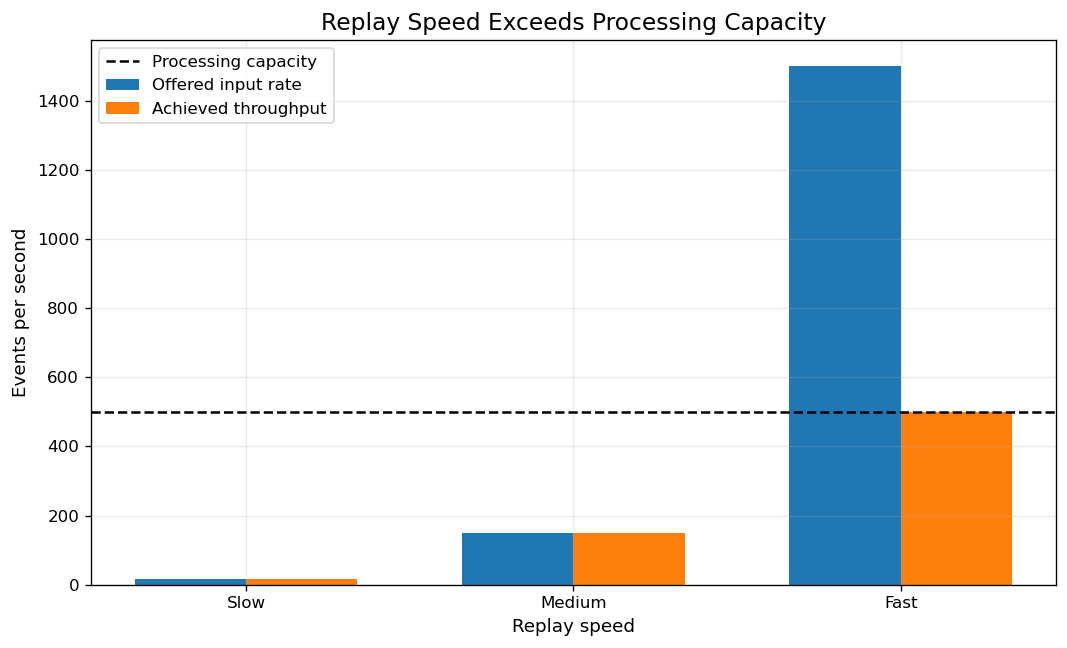

Saved: /Users/VV/Documents/GitHub/smokewatch-replay/reports/figures/replay_throughput_vs_capacity.png


In [24]:
throughput_chart_data = (
    report_metrics[
        report_metrics[
            "delay_profile"
        ].eq("none")
    ]
    .set_index("speed_name")
    .loc[speed_order]
    .reset_index()
)

x_positions = np.arange(
    len(throughput_chart_data)
)

bar_width = 0.34

figure, axis = plt.subplots(
    figsize=(9, 5.5)
)

axis.bar(
    x_positions - bar_width / 2,
    throughput_chart_data[
        "offered_input_rate_eps"
    ],
    width=bar_width,
    label="Offered input rate",
)

axis.bar(
    x_positions + bar_width / 2,
    throughput_chart_data[
        "achieved_throughput_eps"
    ],
    width=bar_width,
    label="Achieved throughput",
)

axis.axhline(
    processing_capacity_events_per_second,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Processing capacity",
)

axis.set_title(
    "Replay Speed Exceeds Processing Capacity"
)

axis.set_xlabel(
    "Replay speed"
)

axis.set_ylabel(
    "Events per second"
)

axis.set_xticks(
    x_positions,
    [
        "Slow",
        "Medium",
        "Fast",
    ],
)

axis.legend()

figure.tight_layout()

throughput_figure_path = (
    report_figure_directory
    / "replay_throughput_vs_capacity.png"
)

figure.savefig(
    throughput_figure_path,
    bbox_inches="tight",
)

plt.show()

print(
    "Saved:",
    throughput_figure_path,
)

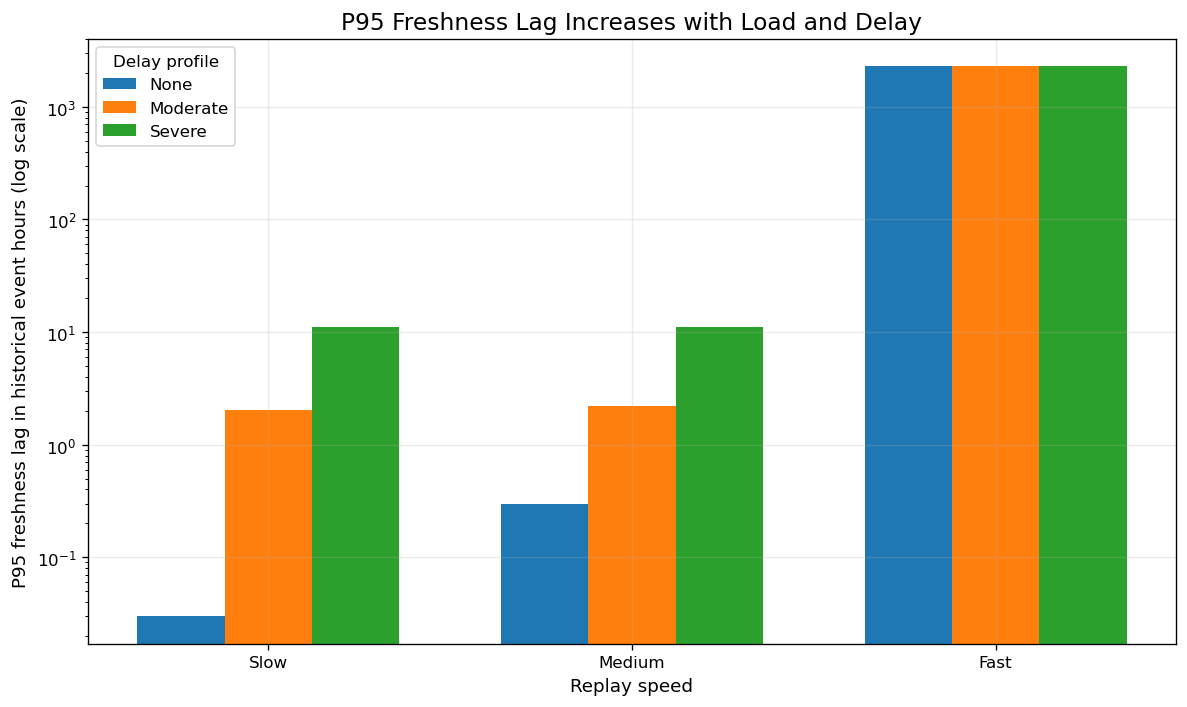

Saved: /Users/VV/Documents/GitHub/smokewatch-replay/reports/figures/replay_p95_freshness_lag.png


In [25]:
freshness_chart_data = (
    report_metrics
    .pivot(
        index="speed_name",
        columns="delay_profile",
        values="p95_freshness_lag_event_hours",
    )
    .loc[
        speed_order,
        delay_order,
    ]
)

x_positions = np.arange(
    len(speed_order)
)

bar_width = 0.24

figure, axis = plt.subplots(
    figsize=(10, 6)
)

for delay_index, delay_profile in enumerate(
    delay_order
):
    axis.bar(
        x_positions
        + (
            delay_index - 1
        )
        * bar_width,
        freshness_chart_data[
            delay_profile
        ].to_numpy(),
        width=bar_width,
        label=delay_profile.title(),
    )

axis.set_yscale("log")

axis.set_title(
    "P95 Freshness Lag Increases with Load and Delay"
)

axis.set_xlabel(
    "Replay speed"
)

axis.set_ylabel(
    "P95 freshness lag in historical event hours (log scale)"
)

axis.set_xticks(
    x_positions,
    [
        "Slow",
        "Medium",
        "Fast",
    ],
)

axis.legend(
    title="Delay profile"
)

figure.tight_layout()

freshness_figure_path = (
    report_figure_directory
    / "replay_p95_freshness_lag.png"
)

figure.savefig(
    freshness_figure_path,
    bbox_inches="tight",
)

plt.show()

print(
    "Saved:",
    freshness_figure_path,
)

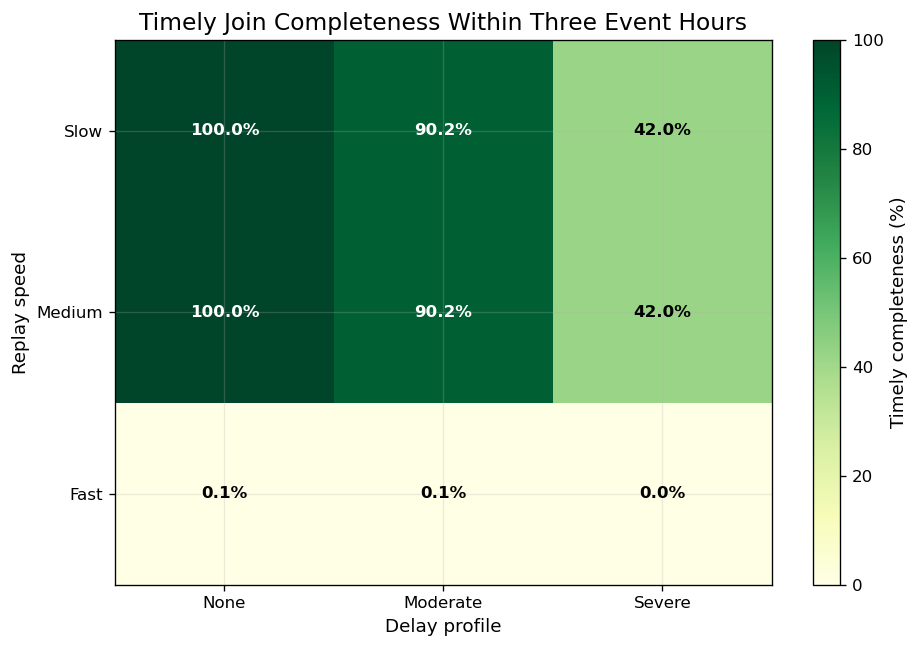

Saved: /Users/VV/Documents/GitHub/smokewatch-replay/reports/figures/replay_timely_join_completeness.png


In [28]:
completeness_matrix = (
    report_metrics
    .pivot(
        index="speed_name",
        columns="delay_profile",
        values="timely_join_completeness_percent",
    )
    .loc[
        speed_order,
        delay_order,
    ]
)

figure, axis = plt.subplots(
    figsize=(8, 5.5)
)

heatmap_image = axis.imshow(
    completeness_matrix.to_numpy(),
    cmap="YlGn",
    vmin=0,
    vmax=100,
    aspect="auto",
)

axis.set_title(
    "Timely Join Completeness Within Three Event Hours"
)

axis.set_xlabel(
    "Delay profile"
)

axis.set_ylabel(
    "Replay speed"
)

axis.set_xticks(
    np.arange(len(delay_order)),
    [
        "None",
        "Moderate",
        "Severe",
    ],
)

axis.set_yticks(
    np.arange(len(speed_order)),
    [
        "Slow",
        "Medium",
        "Fast",
    ],
)

for row_index in range(
    len(speed_order)
):
    for column_index in range(
        len(delay_order)
    ):
        cell_value = (
            completeness_matrix.iloc[
                row_index,
                column_index,
            ]
        )

        text_color = (
            "white"
            if cell_value >= 65
            else "black"
        )

        axis.text(
            column_index,
            row_index,
            f"{cell_value:.1f}%",
            ha="center",
            va="center",
            color=text_color,
            fontweight="bold",
        )

color_bar = figure.colorbar(
    heatmap_image,
    ax=axis,
)

color_bar.set_label(
    "Timely completeness (%)"
)

figure.tight_layout()

completeness_figure_path = (
    report_figure_directory
    / "replay_timely_join_completeness.png"
)

figure.savefig(
    completeness_figure_path,
    bbox_inches="tight",
)

plt.show()

print(
    "Saved:",
    completeness_figure_path,
)

In [27]:
report_metrics_path = (
    report_table_directory
    / "replay_scenario_metrics.csv"
)

delay_effects_path = (
    report_table_directory
    / "replay_delay_effects.csv"
)

speed_comparison_path = (
    report_table_directory
    / "replay_speed_comparison.csv"
)

report_metrics.to_csv(
    report_metrics_path,
    index=False,
)

delay_effects.to_csv(
    delay_effects_path,
    index=False,
)

no_delay_speed_comparison.to_csv(
    speed_comparison_path,
    index=False,
)


fast_no_delay = (
    report_metrics[
        report_metrics[
            "scenario_id"
        ].eq("fast__none")
    ]
    .iloc[0]
)

medium_no_delay = (
    report_metrics[
        report_metrics[
            "scenario_id"
        ].eq("medium__none")
    ]
    .iloc[0]
)

print("Analysis outputs saved successfully.")

print(
    "1. Medium replay remained within capacity:",
    round(
        medium_no_delay[
            "achieved_throughput_eps"
        ],
        2,
    ),
    "events/second.",
)

print(
    "2. Fast replay offered",
    round(
        fast_no_delay[
            "offered_input_rate_eps"
        ],
        2,
    ),
    "events/second but achieved",
    round(
        fast_no_delay[
            "achieved_throughput_eps"
        ],
        2,
    ),
    "events/second.",
)

print(
    "3. Fast replay maximum queue depth:",
    int(
        fast_no_delay[
            "maximum_queue_depth"
        ]
    ),
)

print(
    "4. Fast replay P95 processing latency:",
    round(
        fast_no_delay[
            "p95_processing_latency_seconds"
        ],
        3,
    ),
    "seconds.",
)

print("\nSaved tables:")

print(report_metrics_path)
print(delay_effects_path)
print(speed_comparison_path)

print("\nSaved figures:")

print(throughput_figure_path)
print(freshness_figure_path)
print(completeness_figure_path)

Analysis outputs saved successfully.
1. Medium replay remained within capacity: 150.09 events/second.
2. Fast replay offered 1500.0 events/second but achieved 500.0 events/second.
3. Fast replay maximum queue depth: 12006
4. Fast replay P95 processing latency: 22.806 seconds.

Saved tables:
/Users/VV/Documents/GitHub/smokewatch-replay/reports/tables/replay_scenario_metrics.csv
/Users/VV/Documents/GitHub/smokewatch-replay/reports/tables/replay_delay_effects.csv
/Users/VV/Documents/GitHub/smokewatch-replay/reports/tables/replay_speed_comparison.csv

Saved figures:
/Users/VV/Documents/GitHub/smokewatch-replay/reports/figures/replay_throughput_vs_capacity.png
/Users/VV/Documents/GitHub/smokewatch-replay/reports/figures/replay_p95_freshness_lag.png
/Users/VV/Documents/GitHub/smokewatch-replay/reports/figures/replay_timely_join_completeness.png


## Key Findings

1. **Replay speed created a clear capacity threshold.** Slow replay offered
15 events per second and medium replay offered 150 events per second.
Both remained below the simulated processing capacity of 500 events per
second.

2. **Fast replay overloaded the processor.** It offered 1,500 events per
second but achieved only 500 events per second. The queue grew to 12,006
events, and P95 processing latency increased to 22.806 seconds.

3. **Delayed records affected timeliness even when capacity was sufficient.**
For slow and medium replay, moderate delay reduced timely join completeness
from 100% to 90.2%. Severe delay reduced it to 42.0%.

4. **Capacity overload had a larger effect than injected delay.** Under fast
replay, timely join completeness was approximately 0.1% even without delayed
records. Additional delays had little visible effect because the processing
queue was already the dominant source of lateness.

5. **All scenarios eventually reached 100% final join completeness.** The
difference was whether the three source records became available before the
three-event-hour watermark.

## Interpretation of Correctness and Freshness

`timely_join_completeness_percent` measures the percentage of county-hour
keys for which NASA FIRMS, EPA PM2.5, and NOAA weather records were all
processed within the three-event-hour watermark.

`watermark_correctness_percent` uses the same structural requirement. A
result is treated as correct at the watermark only when all three source
records are available. It does not evaluate whether the original source
measurements are scientifically correct.

Freshness lag is reported in equivalent historical event hours. The very
large fast-replay value shows that the queue delay became larger than the
compressed replay timeline; it does not mean that the original historical
records were actually delayed by that many real-world hours.

## Simulation Limitations

- The 500-event-per-second processing capacity is a controlled parameter,
not a measured Kafka or Spark benchmark.
- Processing time is modeled as constant for every event.
- The simulation uses one logical processor and does not model partitions,
parallel workers, network delay, retries, or serialization overhead.
- Injected delays are deterministic and reproducible, but they are designed
experimental conditions rather than measured source-publication delays.
- Final join completeness is structural. Measurement availability remains
separate, such as the missing EPA coverage for Lassen County.
- The Dixie Fire is a focused California wildfire case study, so results
should not automatically be generalized to every fire or data source.

## Conclusion

The experiment shows that replay velocity and delayed records affect the
pipeline in different ways. Below processing capacity, injected delays mainly
reduce freshness and timely join completeness while throughput remains stable.
Above processing capacity, the queue becomes the main limitation: throughput
stops increasing, latency rises sharply, and almost no county-hour joins finish
within the watermark.

This supports using replay speed, queue depth, latency, freshness, and timely
join completeness together when evaluating a multi-source wildfire pipeline.